In [1]:
# Setup
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")

import json

import numpy as np
import pandas as pd
import h5py
import torch
from chronos import Chronos2Pipeline
from chronos.chronos2.preprocess import from_data_frame

device = "cuda" if torch.cuda.is_available() else "cpu"
pipeline = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map=device)
print(f"Loaded Chronos-2 on {device}")

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Loaded Chronos-2 on cuda


In [2]:
# Load data: one series per simulation run, each with its own disturbance realization
DATA_FILES = [   # simulated for fine-tuning, separate from the test data
    "tep_sp_finetune_noisy.h5",           # seed 1000, 1000 h
    "tep_sp_finetune_seed1001_noisy.h5",  # 500 h
    "tep_sp_finetune_seed1002_noisy.h5",  # 500 h
]
DATA_FILE = ", ".join(DATA_FILES)


def read_names(ds):
    return [n.decode() if isinstance(n, bytes) else str(n) for n in ds.attrs["names"]]


def load_run(path):
    groups = {}
    with h5py.File(path, "r") as f:
        assert not f.attrs["shutdown"], f"{path}: the plant shut down"
        time_h = f["t"][()] / 3600
        for key in ["xmeas", "xmv", "dist", "sp"]:
            groups[key] = (f[key][()], read_names(f[key]))
        if "y" in f:   # true valve positions
            groups["valve"] = (f["y"][:, 38:50], read_names(f["y"])[38:50])
        config = json.loads(f.attrs["config"])
    data = {"time_h": time_h}
    columns, labels = {}, {}
    for group, (values, names) in groups.items():
        columns[group] = [f"{group}_{i}" for i in range(1, values.shape[1] + 1)]
        for col, v, name in zip(columns[group], values.T, names):
            data[col] = v
            labels[col] = name
    run = pd.DataFrame(data)
    run.insert(0, "item_id", f"seed{config['seed']}")
    run.insert(1, "timestamp", pd.date_range("2026-01-01", periods=len(run), freq=f"{config['record_every']}s"))
    return run, columns, labels, config


runs, configs = [], []
for path in DATA_FILES:
    run, COLUMNS, LABELS, config = load_run(path)
    runs.append(run)
    configs.append(config)
CHANGED = sorted({k for k, _, _ in configs[0]["setpoint_schedule"]})   # set points changed in the runs
assert all(sorted({k for k, _, _ in c["setpoint_schedule"]}) == CHANGED for c in configs)

TARGET_COLUMNS = COLUMNS["xmeas"] + COLUMNS["xmv"]
for path, run in zip(DATA_FILES, runs):
    print(f"{path}: {len(run)} samples ({run['time_h'].iloc[-1]:.0f} h)")
print(f"{len(TARGET_COLUMNS)} targets, changed set points: {CHANGED}")

tep_sp_finetune_noisy.h5: 10000 samples (1000 h)
tep_sp_finetune_seed1001_noisy.h5: 5000 samples (500 h)
tep_sp_finetune_seed1002_noisy.h5: 5000 samples (500 h)
53 targets, changed set points: [5, 7, 8, 11, 13, 14, 15, 17, 18, 19, 20]


In [3]:
# Training and validation inputs
USE_SP = True        # changed set points (11), known over the forecast
USE_DIST = False     # disturbance signals (12), known over the forecast
CONTEXT_LENGTH = 2048
PREDICTION_LENGTH = 256
MIN_PAST = 256       # shortest context sampled in training
VAL_FRACTION = 0.25  # held out from the end of every run, so validation covers every disturbance realization
VAL_STRIDE = 128     # samples between the starts of the validation forecasts

COVARIATES = ([f"sp_{k}" for k in CHANGED] if USE_SP else []) + (COLUMNS["dist"] if USE_DIST else [])
ROWS_PER_WINDOW = len(TARGET_COLUMNS) + len(COVARIATES)   # fit() counts the batch size in rows, one per target and covariate

# Validation scores the last PREDICTION_LENGTH samples of each series: one series per forecast that lies in the
# held-out part of a run, with its context reaching back into the training part
VAL_WINDOW = CONTEXT_LENGTH + PREDICTION_LENGTH
fit_parts, val_parts = [], []
for run in runs:
    run = run[["item_id", "timestamp"] + TARGET_COLUMNS + COVARIATES]
    name = run["item_id"].iloc[0]
    split = int(len(run) * (1 - VAL_FRACTION))
    fit_parts.append(run.iloc[:split])
    n_val = 0
    for end in range(split + PREDICTION_LENGTH, len(run) + 1, VAL_STRIDE):
        part = run.iloc[max(end - VAL_WINDOW, 0):end].copy()
        part["item_id"] = f"{name}_val_{n_val}"
        val_parts.append(part)
        n_val += 1
    print(f"{name}: training samples 0-{split - 1}, validation {n_val} forecasts in samples {split}-{len(run) - 1}")
fit_df = pd.concat(fit_parts)
val_df = pd.concat(val_parts)

fit_kwargs = dict(
    target_columns=TARGET_COLUMNS,
    prediction_length=PREDICTION_LENGTH,
    known_covariates_names=COVARIATES,
    id_column="item_id",
    timestamp_column="timestamp",
)
fit_inputs = from_data_frame(fit_df, **fit_kwargs)
val_inputs = from_data_frame(val_df, **fit_kwargs)
print(f"{len(TARGET_COLUMNS)} targets, covariates ({len(COVARIATES)}): {', '.join(COVARIATES)}")
print(f"Training: {len(fit_df)} samples in {len(fit_parts)} runs, validation: {len(val_parts)} forecasts of "
      f"{PREDICTION_LENGTH} samples")

seed1000: training samples 0-7499, validation 18 forecasts in samples 7500-9999
seed1001: training samples 0-3749, validation 8 forecasts in samples 3750-4999
seed1002: training samples 0-3749, validation 8 forecasts in samples 3750-4999
53 targets, covariates (11): sp_5, sp_7, sp_8, sp_11, sp_13, sp_14, sp_15, sp_17, sp_18, sp_19, sp_20
Training: 15000 samples in 3 runs, validation: 34 forecasts of 256 samples


In [4]:
# Fine-tune
from transformers import EarlyStoppingCallback

FINETUNE_MODE = "lora"    # "lora": base weights frozen, low-rank adapters trained; "full": all weights trained
LEARNING_RATE = {"full": 1e-5, "lora": 2e-5}[FINETUNE_MODE]
NUM_STEPS = 3000          # most optimizer steps, early stopping usually ends the run sooner
EVAL_STEPS = 50           # validation and checkpoint interval
PATIENCE = 8              # validations without improvement before stopping
WINDOWS_PER_BATCH = 1     # limited by GPU memory (16 GB)
GRAD_ACCUMULATION = 4     # windows per optimizer step = WINDOWS_PER_BATCH x GRAD_ACCUMULATION
COV_TAG = "sp" + ("-dist" if USE_DIST else "")
RUN_NAME = f"chronos-2-tep-{COV_TAG}-{len(DATA_FILES)}runs-ctx{CONTEXT_LENGTH}-{FINETUNE_MODE}"
OUTPUT_DIR = f"chronos-2-finetuned/{RUN_NAME}"

# LoRA adapters (Chronos-2 defaults), only used with FINETUNE_MODE = "lora"
LORA_CONFIG = dict(
    r=8,
    lora_alpha=16,
    target_modules=[
        "self_attention.q",
        "self_attention.k",
        "self_attention.v",
        "self_attention.o",
        "output_patch_embedding.output_layer",
    ],
)

finetuned_pipeline = pipeline.fit(
    inputs=fit_inputs,
    prediction_length=PREDICTION_LENGTH,
    validation_inputs=val_inputs,
    finetune_mode=FINETUNE_MODE,
    lora_config=LORA_CONFIG if FINETUNE_MODE == "lora" else None,
    context_length=CONTEXT_LENGTH,
    min_past=MIN_PAST,
    learning_rate=LEARNING_RATE,
    num_steps=NUM_STEPS,
    batch_size=WINDOWS_PER_BATCH * ROWS_PER_WINDOW,
    output_dir=OUTPUT_DIR,
    finetuned_ckpt_name="finetuned-ckpt",
    gradient_accumulation_steps=GRAD_ACCUMULATION,
    disable_tqdm=True,
    eval_steps=EVAL_STEPS,
    save_steps=EVAL_STEPS,
    logging_steps=EVAL_STEPS,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=PATIENCE)],
)
print(f"Fine-tuning complete: {WINDOWS_PER_BATCH * GRAD_ACCUMULATION} windows per step")

{'loss': '6.465', 'grad_norm': '1.315', 'learning_rate': '1.967e-05', 'epoch': '0.01667'}


{'eval_loss': '6.051', 'eval_runtime': '5.309', 'eval_samples_per_second': '409.9', 'eval_steps_per_second': '6.404', 'epoch': '0.01667'}


{'loss': '6.362', 'grad_norm': '1.215', 'learning_rate': '1.934e-05', 'epoch': '0.03333'}


{'eval_loss': '5.927', 'eval_runtime': '5.434', 'eval_samples_per_second': '400.4', 'eval_steps_per_second': '6.257', 'epoch': '0.03333'}


{'loss': '6.417', 'grad_norm': '2.348', 'learning_rate': '1.901e-05', 'epoch': '0.05'}


{'eval_loss': '5.866', 'eval_runtime': '5.325', 'eval_samples_per_second': '408.7', 'eval_steps_per_second': '6.385', 'epoch': '0.05'}


... (48 outputs left out)

{'loss': '5.739', 'grad_norm': '4.73', 'learning_rate': '1.067e-05', 'epoch': '0.4667'}


{'eval_loss': '5.684', 'eval_runtime': '5.292', 'eval_samples_per_second': '411.2', 'eval_steps_per_second': '6.425', 'epoch': '0.4667'}


{'train_runtime': '2052', 'train_samples_per_second': '374.2', 'train_steps_per_second': '1.462', 'train_loss': '6.002', 'epoch': '0.4667'}


Fine-tuning complete: 4 windows per step


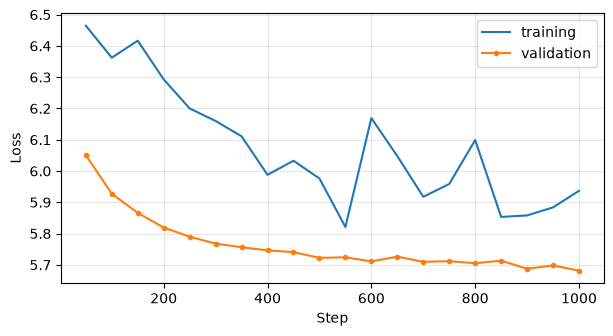

Best validation loss 5.6813 at step 1000 (loaded at the end of training), stopped at step 1000


In [5]:
# Training and validation loss
import glob
import matplotlib.pyplot as plt

state_files = sorted(glob.glob(f"{OUTPUT_DIR}/checkpoint-*/trainer_state.json"), key=os.path.getmtime)
history = json.load(open(state_files[-1]))["log_history"]
train_log = pd.DataFrame([h for h in history if "loss" in h])
val_log = pd.DataFrame([h for h in history if "eval_loss" in h])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(train_log["step"], train_log["loss"], label="training")
ax.plot(val_log["step"], val_log["eval_loss"], marker="o", ms=3, label="validation")
ax.set_xlabel("Step")
ax.set_ylabel("Loss")
ax.grid(alpha=0.3)
ax.legend()
plt.show()
best = val_log.loc[val_log["eval_loss"].idxmin()]
print(f"Best validation loss {best['eval_loss']:.4f} at step {int(best['step'])} (loaded at the end of training), "
      f"stopped at step {int(val_log['step'].max())}")

In [6]:
# Save the fine-tuned model and push it to the Hugging Face Hub
SAVE_DIR = f"{RUN_NAME}-final"
finetuned_pipeline.save_pretrained(SAVE_DIR)
print(f"Saved fine-tuned pipeline to {SAVE_DIR}")

# Requires `hf auth login`
HF_REPO_ID = f"Imker0311/{RUN_NAME}"
PUSH_TO_HUB = True
PRIVATE_REPO = True

if PUSH_TO_HUB:
    from huggingface_hub import HfApi

    api = HfApi()
    api.create_repo(repo_id=HF_REPO_ID, repo_type="model", private=PRIVATE_REPO, exist_ok=True)
    api.upload_folder(
        folder_path=SAVE_DIR,
        repo_id=HF_REPO_ID,
        repo_type="model",
        commit_message=f"{FINETUNE_MODE} fine-tune (r={LORA_CONFIG['r']}) on {DATA_FILE}: covariates={COVARIATES}, "
                       f"ctx={CONTEXT_LENGTH}, h={PREDICTION_LENGTH}, min_past={MIN_PAST}, best of {NUM_STEPS} steps x "
                       f"{WINDOWS_PER_BATCH * GRAD_ACCUMULATION} windows, lr={LEARNING_RATE}",
    )
    print(f"Pushed to https://huggingface.co/{HF_REPO_ID}")
else:
    print("PUSH_TO_HUB is False, saved locally only")

Saved fine-tuned pipeline to chronos-2-tep-sp-3runs-ctx2048-lora-final


Pushed to https://huggingface.co/Imker0311/chronos-2-tep-sp-3runs-ctx2048-lora
